======================================================

**Milestone 2**

Nama    : Putri Dyah Masyitah <br>
Batch   : RMT-061<br>

Program ini dibuat untuk memprediksi kelas penyakit Cadiovascular menggunakan Machine Learning dengan Algoritma SVM, KNN, Decision Tree, Random Forest dan GradientBoost.


======================================================

## Problem Background
**Cadiosvacular Disease** adalah penyakit yang terjadi karena adanya gangguan pada jantung dan pembuluh darah. Penyakit jantung dan stroke merupakan penyakit cardiovascular yang terkenal. Berdasarkan WHO, estimasi 19.8 juta orang meninggal di 2022, dikarenakan CVD. 85% diantaranya serangan jantung dan stroke.<br> Di Indonesia, penyakit cardiovascular menyebabkan sekitar 651.481 kematian setiap tahunnya, yang dikarenakan pola hidup tidak sehat, seperti terlalu makan makanan berlemak, tidak rutin berolahraga, kebiasaan merokok, dan kebiasaan konsumsi alkohol (Alodokter, 2026). <br> Sebagai bentuk mitigasi penangangan cardiovascular awal yang cepat, dibutuhkan data screening yang dapat memprediksi seseorang memiliki potensi kelas Cardiovascular.

**Understanding The Problem**:<br>
Memahami tipe kelas penyakit cardiovascular dan cara penanganan pertama. Data screening sebagai data awal untuk prediksi seseorang memiliki potensi penyakit Cardiovascular menggunakan machine learning, algoritma Support Vector Machine (SVM), KNN, Decision Tree, Random Forest dan GradientBoost.

User: Publik yang memiliki concern terkait penyakit cardiovascular.

## Data Understanding

Dataset ini adalah real-case data yang berasal Jamalpur Medical College Hospital, Jamalpur, Bangladesh dari 20 January 2024 hingga 1 January 2025. Link dataset dari Kaggle: <https://www.kaggle.com/datasets/jocelyndumlao/cair-cvd-2025-cardiovascular-risk-from-bangladesh?resource=download>.<br>
**target: CVD Risk Level**<br>
Dataset memiliki 22 kolom dan 1529 baris.<br>
Daftar kolom:<br>
|   Kolom   |   Arti    |
|----------|-----------|
|   'Sex'   |   Gender  |
|   'Age'   | Umur  |
|   'Weight'    | Berat badan dalam satuan kg|
|   'Height_m'  | tinggi badan dalam satuan meter|
|   'BMI' | body mass index|
|'Abdominal Circumference' | lingkar perut dalam satuan cm|
|'Blood Pressure (mmHg)' | tekanan darah dalam satuan mmHg|
|'Total Cholesterol (mg/dL)' | total kolesterol dalam satuan mg/dL|
|'HDL' | lemak baik/ High Density Lipoprotein dalam satuan mg/dL|
|'Fasting Blood Sugar' | Gula darah saat puasa dalam stauan mg/dL|
|'Smoking Status' | status perokok, ya atau tidak|
|'Diabetes Status' | status diabetes, ya atau tidak|
|'Physical Activity Level' | level aktivitas sehari-hari, Low-Moderate,High|
|'Family History of CVD' | riwayat penyakit CVD di keluarga, ya atau tidak|
|'CVD Risk Level' |  level resiko CVD, low-intemediary-high|
|'Height_cm' |  tinggi badan dalam satuan cm|
|'Waist-to-Height Ratio' | rasio pinggang-tinggi badan|
|'Systolic BP' | tensi darah sistolik|
|'Diastolic BP' | tensi darah diastolik|
|'Blood Pressure Category' | kategori tekanan darah|
|'Estimated LDL' | estimasi lemak jahat/ Low Density Lipoprotein dalam satuan mg/dL|
|'CVD Risk Score' | skor resiko CVD|

In [ ]:
# import library and packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import randint, uniform
import warnings
warnings.filterwarnings('ignore')

# Preprocessing
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, LabelEncoder
from feature_engine.outliers import Winsorizer
from sklearn.compose import ColumnTransformer

# Modeling
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

# Model Evaluation
from sklearn.metrics import (classification_report,
                             ConfusionMatrixDisplay,
                             precision_score,
                             recall_score,
                             f1_score,
                             roc_auc_score,
                             roc_curve)

# Saving Files
import pickle

## Loading Data
Data loading and data cleaning.

In [ ]:
# loading dataset 1
df_raw = pd.read_csv(r'../P1M2_putri_dataset_cardiovascular.csv')

# copy dataframe
df=df_raw

In [ ]:
# preview first 10 data
df.head(10)

,Sex,Age,Weight (kg),Height (m),BMI,Abdominal Circumference (cm),Blood Pressure (mmHg),Total Cholesterol (mg/dL),HDL (mg/dL),Fasting Blood Sugar (mg/dL),...,Physical Activity Level,Family History of CVD,CVD Risk Level,Height (cm),Waist-to-Height Ratio,Systolic BP,Diastolic BP,Blood Pressure Category,Estimated LDL (mg/dL),CVD Risk Score
0,F,32.0,69.1,1.71,23.6,86.2,125/79,248.0,78.0,111.0,...,Low,N,INTERMEDIARY,171.0,0.504,125.0,79.0,Elevated,140.0,17.93
1,F,55.0,118.7,1.69,41.6,82.5,139/70,162.0,50.0,135.0,...,High,Y,HIGH,169.0,0.488,139.0,70.0,Hypertension Stage 1,82.0,20.51
2,M,NaN,NaN,1.83,26.9,106.7,104/77,103.0,73.0,114.0,...,High,Y,INTERMEDIARY,183.0,0.583,104.0,77.0,Normal,0.0,12.64
3,M,44.0,108.3,1.80,33.4,96.6,140/83,134.0,46.0,91.0,...,High,Y,INTERMEDIARY,NaN,0.537,140.0,83.0,Hypertension Stage 1,58.0,16.36
4,F,32.0,99.5,1.86,28.8,102.7,144/83,146.0,64.0,141.0,...,High,N,INTERMEDIARY,186.0,0.552,144.0,83.0,Hypertension Stage 1,52.0,17.88
5,F,58.0,117.9,1.87,33.7,81.4,142/90,156.0,67.0,82.0,...,Moderate,Y,HIGH,187.0,0.435,142.0,90.0,Hypertension Stage 2,59.0,16.96
6,M,33.0,117.9,1.82,35.6,74.8,96/63,184.0,66.0,87.0,...,Low,N,INTERMEDIARY,182.0,0.411,96.0,63.0,Normal,88.0,17.60
7,M,55.0,100.1,1.74,33.1,96.6,115/73,287.0,40.0,96.0,...,Moderate,N,HIGH,174.0,0.555,115.0,73.0,Normal,217.0,18.11
8,F,37.0,110.1,1.86,31.8,92.4,107/95,177.0,68.0,70.0,...,High,N,INTERMEDIARY,186.0,0.497,NaN,95.0,Hypertension Stage 2,79.0,15.25
9,F,58.0,97.6,1.86,28.2,74.6,133/83,281.0,68.0,126.0,...,Moderate,N,INTERMEDIARY,186.0,0.401,133.0,83.0,Hypertension Stage 1,183.0,17.91


In [ ]:
# preview last 10 data
df.tail(10)

,Sex,Age,Weight (kg),Height (m),BMI,Abdominal Circumference (cm),Blood Pressure (mmHg),Total Cholesterol (mg/dL),HDL (mg/dL),Fasting Blood Sugar (mg/dL),...,Physical Activity Level,Family History of CVD,CVD Risk Level,Height (cm),Waist-to-Height Ratio,Systolic BP,Diastolic BP,Blood Pressure Category,Estimated LDL (mg/dL),CVD Risk Score
1519,F,53.0,101.530,1.727,35.423,110.121,143/67,174.0,38.0,161.0,...,High,Y,HIGH,172.657,0.638,143.0,67.0,Hypertension Stage 2,106.0,19.715
1520,M,29.0,89.388,1.716,26.208,78.400,165/72,223.0,49.0,94.0,...,Low,N,LOW,171.635,0.457,165.0,72.0,Hypertension Stage 2,144.0,19.952
1521,F,48.0,116.299,1.665,23.504,107.219,97/74,216.0,82.0,168.0,...,Moderate,N,LOW,166.474,0.644,97.0,74.0,Normal,104.0,15.871
1522,F,41.0,117.365,1.748,38.310,118.246,105/87,200.0,35.0,87.0,...,High,N,INTERMEDIARY,174.814,0.676,105.0,87.0,Hypertension Stage 1,135.0,18.912
1523,M,63.0,91.625,1.702,35.278,NaN,162/60,189.0,76.0,153.0,...,Moderate,N,INTERMEDIARY,NaN,0.601,162.0,60.0,Hypertension Stage 2,83.0,20.936
1524,F,40.0,72.070,1.889,NaN,95.326,119/66,157.0,60.0,93.0,...,Moderate,Y,LOW,188.894,0.505,119.0,66.0,Normal,67.0,14.300
1525,F,78.0,85.877,1.825,24.426,112.340,102/115,241.0,84.0,NaN,...,Low,N,INTERMEDIARY,182.485,0.616,102.0,115.0,Hypertension Stage 2,127.0,14.805
1526,M,39.0,98.626,1.521,20.055,77.193,150/90,237.0,82.0,147.0,...,High,N,INTERMEDIARY,152.119,0.507,150.0,90.0,Hypertension Stage 2,125.0,18.251
1527,M,71.0,116.163,1.841,29.279,114.197,112/63,193.0,84.0,123.0,...,High,Y,INTERMEDIARY,184.059,0.620,112.0,63.0,Normal,79.0,15.316
1528,F,78.0,111.627,1.867,22.017,97.692,134/67,218.0,68.0,166.0,...,High,N,HIGH,186.735,0.523,134.0,67.0,Hypertension Stage 1,120.0,15.463


In [ ]:
# check data unique
uniques= ['Sex','Smoking Status','Diabetes Status','Family History of CVD', 'CVD Risk Level']

for unique in uniques:
    print(f'Unique values in {unique}: {df[unique].unique()}')

Unique values in Sex: ['F' 'M']
Unique values in Smoking Status: ['N' 'Y']
Unique values in Diabetes Status: ['Y' 'N']
Unique values in Family History of CVD: ['N' 'Y']
Unique values in CVD Risk Level: ['INTERMEDIARY' 'HIGH' 'LOW']


Keempat kolom tersebut merupakan binary categorical yang belum berbentuk bilangan biner.<br>
Dan CVD Risk Level adalah target pada model training, berisi multiclass: `INTEMEDIARY`, `HIGH`, dan `LOW`.

In [ ]:
# check dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1529 entries, 0 to 1528
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Sex                           1529 non-null   object 
 1   Age                           1451 non-null   float64
 2   Weight (kg)                   1448 non-null   float64
 3   Height (m)                    1462 non-null   float64
 4   BMI                           1465 non-null   float64
 5   Abdominal Circumference (cm)  1462 non-null   float64
 6   Blood Pressure (mmHg)         1529 non-null   object 
 7   Total Cholesterol (mg/dL)     1456 non-null   float64
 8   HDL (mg/dL)                   1449 non-null   float64
 9   Fasting Blood Sugar (mg/dL)   1462 non-null   float64
 10  Smoking Status                1529 non-null   object 
 11  Diabetes Status               1529 non-null   object 
 12  Physical Activity Level       1529 non-null   object 
 13  Fam

In [ ]:
# check data columns
df.columns

Index(['Sex', 'Age', 'Weight (kg)', 'Height (m)', 'BMI',
       'Abdominal Circumference (cm)', 'Blood Pressure (mmHg)',
       'Total Cholesterol (mg/dL)', 'HDL (mg/dL)',
       'Fasting Blood Sugar (mg/dL)', 'Smoking Status', 'Diabetes Status',
       'Physical Activity Level', 'Family History of CVD', 'CVD Risk Level',
       'Height (cm)', 'Waist-to-Height Ratio', 'Systolic BP', 'Diastolic BP',
       'Blood Pressure Category', 'Estimated LDL (mg/dL)', 'CVD Risk Score'],
      dtype='object')

Ubah nama kolom dengan menghapus nama unit agar memudahkan proses analisis.

In [ ]:
# rename columns name by erasing the units
df.columns = ['Sex', 'Age', 'Weight', 'Height_m', 'BMI',
       'Abdominal Circumference', 'Blood Pressure',
       'Total Cholesterol', 'HDL',
       'Fasting Blood Sugar', 'Smoking Status', 'Diabetes Status',
       'Physical Activity Level', 'Family History of CVD', 'CVD Risk Level',
       'Height_cm', 'Waist-to-Height Ratio', 'Systolic BP', 'Diastolic BP',
       'Blood Pressure Category', 'Estimated LDL', 'CVD Risk Score']

# validate result
df.columns

Index(['Sex', 'Age', 'Weight', 'Height_m', 'BMI', 'Abdominal Circumference',
       'Blood Pressure', 'Total Cholesterol', 'HDL', 'Fasting Blood Sugar',
       'Smoking Status', 'Diabetes Status', 'Physical Activity Level',
       'Family History of CVD', 'CVD Risk Level', 'Height_cm',
       'Waist-to-Height Ratio', 'Systolic BP', 'Diastolic BP',
       'Blood Pressure Category', 'Estimated LDL', 'CVD Risk Score'],
      dtype='object')

Cek missing values di dataset

In [ ]:
# check missing values
df.isnull().sum()

Sex                         0
Age                        78
Weight                     81
Height_m                   67
BMI                        64
Abdominal Circumference    67
Blood Pressure              0
Total Cholesterol          73
HDL                        80
Fasting Blood Sugar        67
Smoking Status              0
Diabetes Status             0
Physical Activity Level     0
Family History of CVD       0
CVD Risk Level              0
Height_cm                  74
Waist-to-Height Ratio      79
Systolic BP                71
Diastolic BP               82
Blood Pressure Category     0
Estimated LDL              69
CVD Risk Score             70
dtype: int64

In [ ]:
# percentage missing values
nan_pct = df.isnull().mean()*100
nan_pct

Sex                        0.000000
Age                        5.101373
Weight                     5.297580
Height_m                   4.381949
BMI                        4.185742
Abdominal Circumference    4.381949
Blood Pressure             0.000000
Total Cholesterol          4.774362
HDL                        5.232178
Fasting Blood Sugar        4.381949
Smoking Status             0.000000
Diabetes Status            0.000000
Physical Activity Level    0.000000
Family History of CVD      0.000000
CVD Risk Level             0.000000
Height_cm                  4.839765
Waist-to-Height Ratio      5.166776
Systolic BP                4.643558
Diastolic BP               5.362982
Blood Pressure Category    0.000000
Estimated LDL              4.512753
CVD Risk Score             4.578156
dtype: float64

- Missing values di beberapa kolom di sekitar 5% per kolom nya. Missing values terindikasi MCAR karena kesalahan input data. Contoh kolom `Systolic BP` (angka atas di tensimeter/ tekanan darah ketika jantung memompa darah ke tubuh) dan `Diastolic BP` (angka bawah di tensimeter/ tekanan darah ketika jantung beristirahat) ada yang missing values, tetapi di `Blood Pressure` datanya lengkap. Maka kolom yang kosong dicoba untuk diisi dengan informasi dari kolom lain.
- Data missing values `Height_m` dan `Height_cm` adalah informasi yang sama, namun beda satuan dan `Height_m` memiliki lebih sedikit missing values.<br>
Solusi: nan di `Height_cm` diisi oleh `Height_m` * 100
- Data missing values `Systolic BP` dan `Diastolic BP`.<br>Bisa dilengkapi dengan kolom `Blood Pressure`, di mana `Systolic BP` adalah tekanan atas, dan `Diastolic BP` adalah tekanan bawah.
- Data missing values di `Abdominal Circumference`.<br> Bisa dilengkapi dengan `Waist-to-Height Ratio` dikali dengan `Height_cm`.
- Data missing values di `Weight`.<br> Bisa dilengkapi dengan `BMI` * `Height_cm`*`Height_cm` dibagi 10000.
- Data missing values di `BMI`.<br> Bisa dilengkapi dengan `Weight`/(`Height_cm` * `Height_cm`)*10000,

In [ ]:
# fillna Height_cm with Height_m
df['Height_cm']=df['Height_cm'].fillna(df['Height_m']*100)

# check numbers of nan in Height_cm
print('total missing values di Height_cm: ',df['Height_cm'].isnull().sum())
print('percentage missing values di Height_cm: ', df['Height_cm'].isnull().mean()*100)

total missing values di Height_cm:  6
percentage missing values di Height_cm:  0.3924133420536298


Handling Missing values `Height_cm` dari 74 data atau 4.83% menjadi 6 data nan atau 0.39%.

In [ ]:
# fillna Systolic BP with Blood Pressure info
df['Systolic BP']=df['Systolic BP'].fillna(
    df['Blood Pressure'].str.split('/').str[0])

# check numbers of nan in Systolic BP
print('total missing values di Systolic BP: ',df['Systolic BP'].isnull().sum())
print('percentage missing values di Systolic BP: ', df['Systolic BP'].isnull().mean()*100)

total missing values di Systolic BP:  0
percentage missing values di Systolic BP:  0.0


In [ ]:
# fillna Diastolic BP with Blood Pressure info
df['Diastolic BP']=df['Diastolic BP'].fillna(
    df['Blood Pressure'].str.split('/').str[1])

# check numbers of nan in Diastolic BP
print('total missing values di Diastolic BP: ',df['Diastolic BP'].isnull().sum())
print('percentage missing values di Diastolic BP: ', df['Diastolic BP'].isnull().mean()*100)

total missing values di Diastolic BP:  0
percentage missing values di Diastolic BP:  0.0


In [ ]:
# fillna Abdominal Circumference
df['Abdominal Circumference']=df['Abdominal Circumference'].fillna(df['Waist-to-Height Ratio']*df['Height_cm'])

# check numbers of nan in Height_cm
print('total missing values di Abdominal Circumference: ',df['Abdominal Circumference'].isnull().sum())
print('percentage missing values di Abdominal Circumference: ', df['Abdominal Circumference'].isnull().mean()*100)

total missing values di Abdominal Circumference:  2
percentage missing values di Abdominal Circumference:  0.13080444735120994


In [ ]:
# fillna Weight
df['Weight']=df['Weight'].fillna(
    df['BMI']*df['Height_cm']*df['Height_cm']/10000)

# check numbers of nan in Weight
print('total missing values di Weight: ',df['Weight'].isnull().sum())
print('percentage missing values di Weight: ', df['Weight'].isnull().mean()*100)

total missing values di Weight:  4
percentage missing values di Weight:  0.2616088947024199


In [ ]:
# fillna BMI
df['BMI']=df['BMI'].fillna(
    df['Weight']/(df['Height_cm']*df['Height_cm'])*10000)

# check numbers of nan in Weight
print('total missing values di BMI: ',df['BMI'].isnull().sum())
print('percentage missing values di BMI: ', df['BMI'].isnull().mean()*100)

total missing values di BMI:  5
percentage missing values di BMI:  0.3270111183780248


In [ ]:
# validate check missing values
df.isnull().sum()

Sex                         0
Age                        78
Weight                      4
Height_m                   67
BMI                         5
Abdominal Circumference     2
Blood Pressure              0
Total Cholesterol          73
HDL                        80
Fasting Blood Sugar        67
Smoking Status              0
Diabetes Status             0
Physical Activity Level     0
Family History of CVD       0
CVD Risk Level              0
Height_cm                   6
Waist-to-Height Ratio      79
Systolic BP                 0
Diastolic BP                0
Blood Pressure Category     0
Estimated LDL              69
CVD Risk Score             70
dtype: int64

In [ ]:
# recheck dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1529 entries, 0 to 1528
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Sex                      1529 non-null   object 
 1   Age                      1451 non-null   float64
 2   Weight                   1525 non-null   float64
 3   Height_m                 1462 non-null   float64
 4   BMI                      1524 non-null   float64
 5   Abdominal Circumference  1527 non-null   float64
 6   Blood Pressure           1529 non-null   object 
 7   Total Cholesterol        1456 non-null   float64
 8   HDL                      1449 non-null   float64
 9   Fasting Blood Sugar      1462 non-null   float64
 10  Smoking Status           1529 non-null   object 
 11  Diabetes Status          1529 non-null   object 
 12  Physical Activity Level  1529 non-null   object 
 13  Family History of CVD    1529 non-null   object 
 14  CVD Risk Level          

`Systolic BP` dan `Diastolic BP` berubah menjadi object karena di fillna berupa string dari `Blood Pressure`. Perlu Convert kembali ke float

In [ ]:
# convert ke numerical
for col in ['Systolic BP', 'Diastolic BP']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# validate check
df.dtypes

Sex                         object
Age                        float64
Weight                     float64
Height_m                   float64
BMI                        float64
Abdominal Circumference    float64
Blood Pressure              object
Total Cholesterol          float64
HDL                        float64
Fasting Blood Sugar        float64
Smoking Status              object
Diabetes Status             object
Physical Activity Level     object
Family History of CVD       object
CVD Risk Level              object
Height_cm                  float64
Waist-to-Height Ratio      float64
Systolic BP                float64
Diastolic BP               float64
Blood Pressure Category     object
Estimated LDL              float64
CVD Risk Score             float64
dtype: object

In [ ]:
# check duplicates
duplicates = df.duplicated().sum()

Tidak ditemukan data duplikat.

In [ ]:
# preview first 10 data after cleaning
df.head(10)

,Sex,Age,Weight,Height_m,BMI,Abdominal Circumference,Blood Pressure,Total Cholesterol,HDL,Fasting Blood Sugar,...,Physical Activity Level,Family History of CVD,CVD Risk Level,Height_cm,Waist-to-Height Ratio,Systolic BP,Diastolic BP,Blood Pressure Category,Estimated LDL,CVD Risk Score
0,F,32.0,69.10000,1.71,23.6,86.2,125/79,248.0,78.0,111.0,...,Low,N,INTERMEDIARY,171.0,0.504,125.0,79.0,Elevated,140.0,17.93
1,F,55.0,118.70000,1.69,41.6,82.5,139/70,162.0,50.0,135.0,...,High,Y,HIGH,169.0,0.488,139.0,70.0,Hypertension Stage 1,82.0,20.51
2,M,NaN,90.08541,1.83,26.9,106.7,104/77,103.0,73.0,114.0,...,High,Y,INTERMEDIARY,183.0,0.583,104.0,77.0,Normal,0.0,12.64
3,M,44.0,108.30000,1.80,33.4,96.6,140/83,134.0,46.0,91.0,...,High,Y,INTERMEDIARY,180.0,0.537,140.0,83.0,Hypertension Stage 1,58.0,16.36
4,F,32.0,99.50000,1.86,28.8,102.7,144/83,146.0,64.0,141.0,...,High,N,INTERMEDIARY,186.0,0.552,144.0,83.0,Hypertension Stage 1,52.0,17.88
5,F,58.0,117.90000,1.87,33.7,81.4,142/90,156.0,67.0,82.0,...,Moderate,Y,HIGH,187.0,0.435,142.0,90.0,Hypertension Stage 2,59.0,16.96
6,M,33.0,117.90000,1.82,35.6,74.8,96/63,184.0,66.0,87.0,...,Low,N,INTERMEDIARY,182.0,0.411,96.0,63.0,Normal,88.0,17.60
7,M,55.0,100.10000,1.74,33.1,96.6,115/73,287.0,40.0,96.0,...,Moderate,N,HIGH,174.0,0.555,115.0,73.0,Normal,217.0,18.11
8,F,37.0,110.10000,1.86,31.8,92.4,107/95,177.0,68.0,70.0,...,High,N,INTERMEDIARY,186.0,0.497,107.0,95.0,Hypertension Stage 2,79.0,15.25
9,F,58.0,97.60000,1.86,28.2,74.6,133/83,281.0,68.0,126.0,...,Moderate,N,INTERMEDIARY,186.0,0.401,133.0,83.0,Hypertension Stage 1,183.0,17.91


## Exploratory Data Analysis

In [ ]:
# describe dataset
df.describe()

,Age,Weight,Height_m,BMI,Abdominal Circumference,Total Cholesterol,HDL,Fasting Blood Sugar,Height_cm,Waist-to-Height Ratio,Systolic BP,Diastolic BP,Estimated LDL,CVD Risk Score
count,1451.000000,1525.000000,1462.000000,1524.000000,1527.00000,1456.000000,1449.000000,1462.000000,1523.00000,1450.000000,1529.000000,1529.000000,1460.000000,1459.000000
mean,47.025500,85.955426,1.754111,28.417486,91.73720,198.539148,56.197378,117.485636,175.38360,0.525727,125.502289,82.956181,111.550685,16.960925
std,12.421063,21.134289,0.113090,7.033672,12.82685,57.794099,16.066754,30.289174,11.26986,0.081213,22.025423,14.711449,58.866220,2.436192
min,25.000000,46.651533,1.502000,15.000000,70.00000,100.000000,30.000000,70.000000,150.00000,0.360000,90.000000,60.000000,-18.000000,10.530000
25%,37.000000,67.057000,1.660000,22.600000,80.40350,150.000000,42.000000,92.000000,166.00000,0.460000,107.000000,71.000000,61.000000,15.205000
50%,46.000000,86.750000,1.755000,28.144500,91.60000,197.000000,56.000000,115.000000,175.69400,0.522000,125.000000,82.000000,109.000000,16.880000
75%,55.000000,105.000000,1.845500,33.900000,102.26600,249.000000,70.000000,138.000000,184.20350,0.583750,141.000000,93.000000,159.000000,18.630000
max,79.000000,143.766169,2.000000,46.200000,119.99600,300.000000,89.000000,198.000000,199.96000,0.787000,179.000000,119.000000,237.000000,24.170000


In [ ]:
df.columns

Index(['Sex', 'Age', 'Weight', 'Height_m', 'BMI', 'Abdominal Circumference',
       'Blood Pressure', 'Total Cholesterol', 'HDL', 'Fasting Blood Sugar',
       'Smoking Status', 'Diabetes Status', 'Physical Activity Level',
       'Family History of CVD', 'CVD Risk Level', 'Height_cm',
       'Waist-to-Height Ratio', 'Systolic BP', 'Diastolic BP',
       'Blood Pressure Category', 'Estimated LDL', 'CVD Risk Score'],
      dtype='object')

In [ ]:
# normality test data numerical
num_cols = ['Age',
            'Weight',
            'Height_m',
            'BMI',
            'Abdominal Circumference',
            'Total Cholesterol',
            'HDL',
            'Fasting Blood Sugar',
            'Height_cm',
            'Waist-to-Height Ratio',
            'Systolic BP',
            'Diastolic BP',
            'Estimated LDL',
            'CVD Risk Score']

skewness = df[num_cols].skew()
skewness

Age                        0.484724
Weight                    -0.028611
Height_m                  -0.035405
BMI                        0.142253
Abdominal Circumference    0.128037
Total Cholesterol          0.042764
HDL                        0.112872
Fasting Blood Sugar        0.457942
Height_cm                 -0.040580
Waist-to-Height Ratio      0.323618
Systolic BP                0.375944
Diastolic BP               0.375081
Estimated LDL              0.092266
CVD Risk Score             0.099094
dtype: float64

Distribusi data cenderung normal skewed, ada di range -0.5 hingga 0.5.

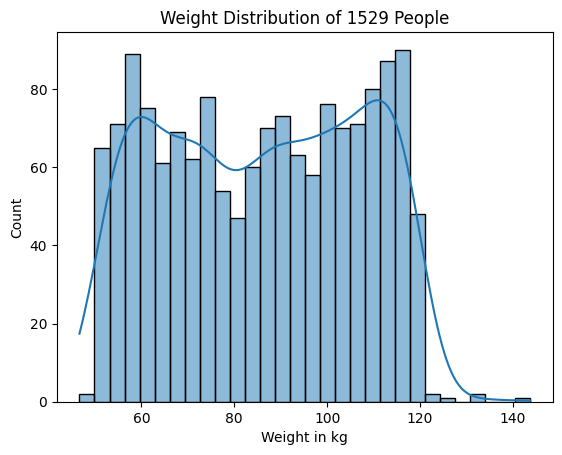

In [ ]:
# plot distribusi Weight
sns.histplot(df['Weight'], bins=30, kde=True)
plt.xlabel('Weight in kg')
plt.title('Weight Distribution of 1529 People')
plt.show()

### EDA: Correlation Test: Sex vs CVD Risk Level

In [ ]:
# create contingency table
contingency_table = pd.crosstab(df['Sex'], df['CVD Risk Level'])

# show table
contingency_table

CVD Risk Level,HIGH,INTERMEDIARY,LOW
Sex,,,
F,379,288,106
M,349,293,114


Diketahui:
- Total partisipan Female 773: 379 orang memiliki potensi High CVD Level; 288 orang memiliki potensi Intemediary CVD Level; dan 106 orang memiliki potensi Low CVD Level.
- Total partisipan Male 773: 349 orang memiliki potensi High CVD Level; 293 orang memiliki potensi Intemediary CVD Level; dan 114 orang memiliki potensi Low CVD Level.

In [ ]:
# chi-squared test Sex vs CVD Risk Level
res = stats.chi2_contingency(contingency_table)

# show stats
print('Correlation statistic value: ', res.statistic)
# show p-values
print('Nilai p-value: ', res.pvalue)

Correlation statistic value:  1.3813604221154339
Nilai p-value:  0.5012350074876697


Nilai p-value diatas critical value 0.05, artinya korelasi antara `Sex` dan `CVD Risk Level` belum cukup bukti/ bukti lemah (asumsi failed to reject *H0*).

### EDA: Correlation Test: Smoking Status vs CVD Risk Level

In [ ]:
# create contingency table
contingency_table2 = pd.crosstab(df['Smoking Status'], df['CVD Risk Level'])

# show table
contingency_table2

CVD Risk Level,HIGH,INTERMEDIARY,LOW
Smoking Status,,,
N,273,350,117
Y,455,231,103


Diketahui:
- Perokok Aktif cenderung memiliki high CVD Risk level daripada Perokok Pasif.<br>

In [ ]:
# chi-squared test Smoking Status vs CVD Risk Level
res = stats.chi2_contingency(contingency_table2)

# show stats
print('Correlation statistic value: ', res.statistic)
# show p-values
print('Nilai p-value: ', res.pvalue)

Correlation statistic value:  69.26523217471677
Nilai p-value:  9.104286991393621e-16


- Nilai korelasi 69.26 menunjukkan di mana ada hubungan positif yang signifikan antara `Smoking Status` dan `CVD Risk Level`.<br>
- Nilai p-value menunjukkan di bawah critical value, artinya secara statistik ada bukti kuat adanya korelasi antara keduanya (asumsi reject *H0*)

### EDA: Correlation Test: Diabetes Status vs CVD Risk Level

In [ ]:
# create contingency table
contingency_table3 = pd.crosstab(df['Diabetes Status'], df['CVD Risk Level'])

# show table
contingency_table3

CVD Risk Level,HIGH,INTERMEDIARY,LOW
Diabetes Status,,,
N,282,349,121
Y,446,232,99


Diketahui:
- Orang yang memiliki diabetes berpotensi memiliki High CVD Risk Level.<br>
- Orang yang tidak memiliki diabetes pun juga memiliki potensi High CVD Risk Level di Intemediary dan Low.

In [ ]:
# chi-squared test Diabetes Status vs CVD Risk Level
res = stats.chi2_contingency(contingency_table3)

# show stats
print('Correlation statistic value: ', res.statistic)
# show p-values
print('Nilai p-value: ', res.pvalue)

Correlation statistic value:  62.31405167701344
Nilai p-value:  2.942223133361889e-14


- Nilai korelasi 62.31 menunjukkan di mana ada hubungan positif yang signifikan antara `Diabetes Status` dan `CVD Risk Level`.<br>
- Nilai p-value menunjukkan di bawah critical value, artinya secara statistik ada bukti kuat adanya korelasi antara keduanya (asumsi reject *H0*)

### EDA: Correlation Test: Physical Activity Level vs CVD Risk Level

In [ ]:
# create contingency table
contingency_table4 = pd.crosstab(df['Physical Activity Level'], df['CVD Risk Level'])

# show table
contingency_table4

CVD Risk Level,HIGH,INTERMEDIARY,LOW
Physical Activity Level,,,
High,211,227,83
Low,301,138,57
Moderate,216,216,80


Diketahui:
- Orang yang memiliki aktivitas fisik tinggi dapat berpotensi memiliki High CVD Risk Level.<br>
- Orang yang memiliki aktivitas fisik rendah dapat juga memiliki potensi High CVD Risk Level di High.

In [ ]:
# chi-squared test Physica Activity Level vs CVD Risk Level
res = stats.chi2_contingency(contingency_table4)

# show stats
print('Correlation statistic value: ', res.statistic)
# show p-values
print('Nilai p-value: ', res.pvalue)

Correlation statistic value:  50.940082267002154
Nilai p-value:  2.297504115736624e-10


- Nilai korelasi 50.94 menunjukkan di mana ada hubungan positif yang signifikan antara `Physical Activity Level` dan `CVD Risk Level`.<br>
- Nilai p-value menunjukkan di bawah critical value, artinya secara statistik ada bukti kuat adanya korelasi antara keduanya (asumsi reject *H0*)

In [ ]:
# check target
df['CVD Risk Level'].value_counts()

CVD Risk Level
HIGH            728
INTERMEDIARY    581
LOW             220
Name: count, dtype: int64

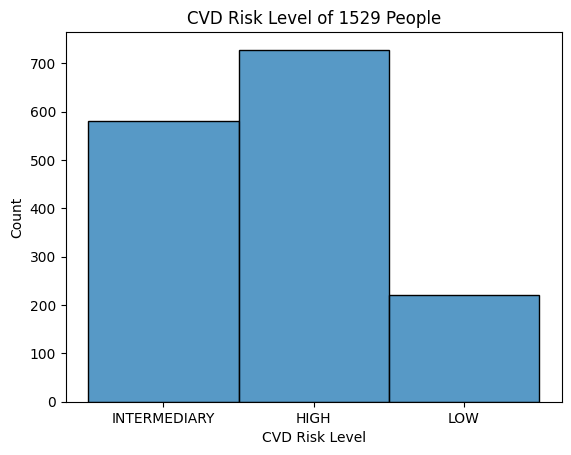

In [ ]:
# plot distribusi CVD Risk Level
sns.histplot(df['CVD Risk Level'], bins=30)
plt.xlabel('CVD Risk Level')
plt.title('CVD Risk Level of 1529 People')
plt.show()

Diketahui:
- Dari 1529 partisipan Jamalpur Medical College Hospital: 728 orang berpotensi memiliki CVD Risk Level High, 581 orang berpotensi memiliki CVD Risk Level Intemediary, dan 220 orang berpotensi memiliki CVD Risk Level Low.
- CVD Risk Level tidak terlalu imbalance.

## Feature Engineering
Preprocessing data before modeling.

**Feature Engineering Steps**:
1. Cardinality Reduction, skipped because the cardinality is low
2. Split X & y, Train-Test Split
3. Handling Missing Values
4. Handling Outliers, skipped because outliers is under 5% but the outlier analysis is shown in this step.
5. Feature Selection
6. Feature Encoding
7. Feature Scaling
8. Data Balancing, skipped because the target is not extremely imbalanced that needs balancing.

### Feature Engineering - Train Test Split

In [ ]:
# Split X and y
X = df.drop(['CVD Risk Level'], axis=1)
y = df['CVD Risk Level']

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=10
)

# check shape for X_train and X_test
print('Numbers of X_train: ', X_train.shape)
print('Numbers of X_test: ', X_test.shape)

Numbers of X_train:  (1070, 21)
Numbers of X_test:  (459, 21)


In [ ]:
# check y_train
y_train.value_counts()

CVD Risk Level
HIGH            509
INTERMEDIARY    407
LOW             154
Name: count, dtype: int64

In [ ]:
# preview X_train
X_train.head()

,Sex,Age,Weight,Height_m,BMI,Abdominal Circumference,Blood Pressure,Total Cholesterol,HDL,Fasting Blood Sugar,...,Diabetes Status,Physical Activity Level,Family History of CVD,Height_cm,Waist-to-Height Ratio,Systolic BP,Diastolic BP,Blood Pressure Category,Estimated LDL,CVD Risk Score
133,M,35.0,75.300,1.720,25.500,95.400,98/72,137.0,53.0,73.0,...,Y,High,N,172.000,0.555,98.0,72.0,Normal,54.0,14.740
1348,F,57.0,92.923,1.842,33.116,106.315,101/91,158.0,71.0,76.0,...,Y,High,Y,184.172,0.577,101.0,91.0,Hypertension Stage 2,57.0,16.833
543,F,NaN,57.500,1.620,21.900,84.200,118/76,238.0,73.0,126.0,...,N,High,Y,162.000,0.520,118.0,76.0,Normal,135.0,15.040
454,M,39.0,109.900,1.800,33.900,89.400,130/94,267.0,35.0,116.0,...,N,Low,Y,180.000,0.497,130.0,94.0,Hypertension Stage 1,202.0,18.620
1056,F,75.0,115.384,1.744,34.636,102.260,128/97,164.0,31.0,122.0,...,N,Moderate,Y,174.385,0.586,128.0,97.0,Hypertension Stage 2,103.0,16.607


In [ ]:
# preview X_test
X_test.head()

,Sex,Age,Weight,Height_m,BMI,Abdominal Circumference,Blood Pressure,Total Cholesterol,HDL,Fasting Blood Sugar,...,Diabetes Status,Physical Activity Level,Family History of CVD,Height_cm,Waist-to-Height Ratio,Systolic BP,Diastolic BP,Blood Pressure Category,Estimated LDL,CVD Risk Score
1430,M,57.0,51.845,1.755,23.094,112.218,164/78,211.0,30.0,79.0,...,Y,High,Y,175.51,0.639,164.0,78.0,Hypertension Stage 2,151.0,19.039
970,F,39.0,106.700,1.650,39.200,106.500,106/69,201.0,76.0,127.0,...,N,High,N,165.00,0.645,106.0,69.0,Normal,95.0,17.160
666,M,53.0,87.900,1.750,28.700,89.900,140/72,230.0,34.0,112.0,...,N,Moderate,Y,175.00,0.514,140.0,72.0,Hypertension Stage 2,166.0,17.340
550,F,48.0,117.800,1.860,34.100,73.300,116/91,100.0,69.0,150.0,...,N,Low,N,186.00,0.394,116.0,91.0,Hypertension Stage 2,1.0,14.620
526,M,58.0,85.500,1.830,25.500,102.100,98/60,111.0,NaN,124.0,...,Y,Low,Y,183.00,0.558,98.0,60.0,Normal,48.0,14.220


In [ ]:
# check shape for X_train and X_test
print('Numbers of y_train: ', y_train.shape)
print('Numbers of y_test: ', y_test.shape)

Numbers of y_train:  (1070,)
Numbers of y_test:  (459,)


In [ ]:
# check class distribution in test set
np.array(np.unique(y_test, return_counts=True)).T

array([['HIGH', 219],
       ['INTERMEDIARY', 174],
       ['LOW', 66]], dtype=object)

Test set memiliki distribusi data:
- **HIGH** = 219 observasi data.
- **INTEMEDIARY** = 174 observasi data.
- **LOW** = 66 observasi data.

### Splitting Numerical and Categorical Columns on Training and Testing Set

In [ ]:
# set numerical features
num_cols = ['Age',
            'Weight',
            'Height_m',
            'BMI',
            'Abdominal Circumference',
            'Total Cholesterol',
            'HDL',
            'Fasting Blood Sugar',
            'Height_cm',
            'Waist-to-Height Ratio',
            'Systolic BP',
            'Diastolic BP',
            'Estimated LDL',
            'CVD Risk Score']

# set binary categorical features
cat_bin = ['Sex',
               'Smoking Status',
               'Diabetes Status',
               'Family History of CVD']

# set ordinal categorical features
cat_ord = ['Blood Pressure Category', 'Physical Activity Level']

# set nominal categorical features
cat_nom = ['Blood Pressure']

Fitur binary categorical belum berbentuk binary numerik, sehingga di ordinal encode agar membentuk nilai Y=1, N=0, atau F=1, M=0.

### Feature Engineering - Handling Missing Values
Di EDA, semua kolom numerical adalah normal skewed, sehingga handle missing values bisa dilakukan dengan impute Mean.<br>

In [ ]:
# Check missing values for numerical columns
X[num_cols].isnull().sum()

Age                        78
Weight                      4
Height_m                   67
BMI                         5
Abdominal Circumference     2
Total Cholesterol          73
HDL                        80
Fasting Blood Sugar        67
Height_cm                   6
Waist-to-Height Ratio      79
Systolic BP                 0
Diastolic BP                0
Estimated LDL              69
CVD Risk Score             70
dtype: int64

In [ ]:
num_nan_cols = ['Age',
            'Weight',
            'Height_m',
            'BMI',
            'Abdominal Circumference',
            'Total Cholesterol',
            'HDL',
            'Fasting Blood Sugar',
            'Height_cm',
            'Waist-to-Height Ratio',
            'Estimated LDL',
            'CVD Risk Score'] # all num_cols except systolic and diastolic

X_train_num_na = X_train[num_nan_cols]
X_test_num_na = X_test[num_nan_cols]

# check shape of X_train_num_na
X_train_num_na.shape

(1070, 12)

In [ ]:
# preview features that have nan
X_train_num_na

,Age,Weight,Height_m,BMI,Abdominal Circumference,Total Cholesterol,HDL,Fasting Blood Sugar,Height_cm,Waist-to-Height Ratio,Estimated LDL,CVD Risk Score
133,35.0,75.30000,1.720,25.500,95.400,137.0,53.0,73.0,172.000,0.555,54.0,14.740
1348,57.0,92.92300,1.842,33.116,106.315,158.0,71.0,76.0,184.172,0.577,57.0,16.833
543,NaN,57.50000,1.620,21.900,84.200,238.0,73.0,126.0,162.000,0.520,135.0,15.040
454,39.0,109.90000,1.800,33.900,89.400,267.0,35.0,116.0,180.000,0.497,202.0,18.620
1056,75.0,115.38400,1.744,34.636,102.260,164.0,31.0,122.0,174.385,0.586,103.0,16.607
...,...,...,...,...,...,...,...,...,...,...,...,...
474,56.0,50.40000,1.610,19.400,97.300,104.0,39.0,117.0,161.000,0.604,35.0,13.260
610,35.0,91.23192,1.710,31.200,88.100,218.0,NaN,137.0,171.000,0.515,138.0,17.600
324,40.0,91.40000,1.740,30.200,98.700,NaN,35.0,101.0,174.000,0.567,90.0,16.990
1222,30.0,51.72600,1.619,28.906,98.120,113.0,43.0,91.0,161.907,0.606,40.0,16.691


In [ ]:
# Handle missing values by Imputing Data with Mean
mean_imputer = SimpleImputer(strategy='mean')

# fit to X train and transfom to X
mean_imputer.fit(X_train_num_na)
X_train_num_imputed = mean_imputer.transform(X_train_num_na)
X_test_num_imputed = mean_imputer.transform(X_test_num_na)

In [ ]:
# validate results
print('Check missing values numerical features in X_train= ',np.isnan(X_train_num_imputed).sum())
print('Check missing values numerical features in X_test= ',np.isnan(X_test_num_imputed).sum())

Check missing values numerical features in X_train=  0
Check missing values numerical features in X_test=  0


In [ ]:
X_train_num_imputed

array([[ 35.        ,  75.3       ,   1.72      , ...,   0.555     ,
         54.        ,  14.74      ],
       [ 57.        ,  92.923     ,   1.842     , ...,   0.577     ,
         57.        ,  16.833     ],
       [ 46.82433759,  57.5       ,   1.62      , ...,   0.52      ,
        135.        ,  15.04      ],
       ...,
       [ 40.        ,  91.4       ,   1.74      , ...,   0.567     ,
         90.        ,  16.99      ],
       [ 30.        ,  51.726     ,   1.619     , ...,   0.606     ,
         40.        ,  16.691     ],
       [ 59.        ,  85.6       ,   1.89      , ...,   0.471     ,
        134.        ,  14.21      ]])

In [ ]:
print(X_train_num_imputed.shape)
print(X_train_num_na.shape)

print(X_test_num_imputed.shape)
print(X_test_num_na.shape)

(1070, 12)
(1070, 12)
(459, 12)
(459, 12)


In [ ]:
X_train_num_imputed

array([[ 35.        ,  75.3       ,   1.72      , ...,   0.555     ,
         54.        ,  14.74      ],
       [ 57.        ,  92.923     ,   1.842     , ...,   0.577     ,
         57.        ,  16.833     ],
       [ 46.82433759,  57.5       ,   1.62      , ...,   0.52      ,
        135.        ,  15.04      ],
       ...,
       [ 40.        ,  91.4       ,   1.74      , ...,   0.567     ,
         90.        ,  16.99      ],
       [ 30.        ,  51.726     ,   1.619     , ...,   0.606     ,
         40.        ,  16.691     ],
       [ 59.        ,  85.6       ,   1.89      , ...,   0.471     ,
        134.        ,  14.21      ]])

In [ ]:
# change np array into dataframe

X_train_num_imputed = pd.DataFrame(
    X_train_num_imputed,
    columns=num_nan_cols,
    index=X_train_num_na.index)

X_test_num_imputed = pd.DataFrame(
    X_test_num_imputed,
    columns=num_nan_cols,
    index=X_test_num_na.index)

X_train_num_imputed.head()

,Age,Weight,Height_m,BMI,Abdominal Circumference,Total Cholesterol,HDL,Fasting Blood Sugar,Height_cm,Waist-to-Height Ratio,Estimated LDL,CVD Risk Score
133,35.000000,75.300,1.720,25.500,95.400,137.0,53.0,73.0,172.000,0.555,54.0,14.740
1348,57.000000,92.923,1.842,33.116,106.315,158.0,71.0,76.0,184.172,0.577,57.0,16.833
543,46.824338,57.500,1.620,21.900,84.200,238.0,73.0,126.0,162.000,0.520,135.0,15.040
454,39.000000,109.900,1.800,33.900,89.400,267.0,35.0,116.0,180.000,0.497,202.0,18.620
1056,75.000000,115.384,1.744,34.636,102.260,164.0,31.0,122.0,174.385,0.586,103.0,16.607


In [ ]:
# update dataframe num_cols
X_train_num_cols = pd.concat([
    X_train[['Systolic BP','Diastolic BP']],
    X_train_num_imputed],
    axis=1)

X_test_num_cols = pd.concat([
    X_test[['Systolic BP','Diastolic BP']],
    X_test_num_imputed],
    axis=1)

# preview X_train_num_cols
X_train_num_cols.head()

,Systolic BP,Diastolic BP,Age,Weight,Height_m,BMI,Abdominal Circumference,Total Cholesterol,HDL,Fasting Blood Sugar,Height_cm,Waist-to-Height Ratio,Estimated LDL,CVD Risk Score
133,98.0,72.0,35.000000,75.300,1.720,25.500,95.400,137.0,53.0,73.0,172.000,0.555,54.0,14.740
1348,101.0,91.0,57.000000,92.923,1.842,33.116,106.315,158.0,71.0,76.0,184.172,0.577,57.0,16.833
543,118.0,76.0,46.824338,57.500,1.620,21.900,84.200,238.0,73.0,126.0,162.000,0.520,135.0,15.040
454,130.0,94.0,39.000000,109.900,1.800,33.900,89.400,267.0,35.0,116.0,180.000,0.497,202.0,18.620
1056,128.0,97.0,75.000000,115.384,1.744,34.636,102.260,164.0,31.0,122.0,174.385,0.586,103.0,16.607


In [ ]:
# validate results
X_train_num_cols.isnull().sum()

Systolic BP                0
Diastolic BP               0
Age                        0
Weight                     0
Height_m                   0
BMI                        0
Abdominal Circumference    0
Total Cholesterol          0
HDL                        0
Fasting Blood Sugar        0
Height_cm                  0
Waist-to-Height Ratio      0
Estimated LDL              0
CVD Risk Score             0
dtype: int64

Features numerical berhasil diimputasi dan sudah tidak ada missing values.

In [ ]:
# skewness before imputation
skew_before = X_train_num_na.skew()

# skewness after imputation
skew_after = X_train_num_imputed.skew()

print('skewness before mean imputation: \n',skew_before)
print('skewness after mean imputation: \n',skew_after)

skewness before mean imputation: 
 Age                        0.489365
Weight                    -0.018408
Height_m                  -0.055354
BMI                        0.161590
Abdominal Circumference    0.107702
Total Cholesterol          0.008622
HDL                        0.147679
Fasting Blood Sugar        0.456694
Height_cm                 -0.047659
Waist-to-Height Ratio      0.288718
Estimated LDL              0.079273
CVD Risk Score             0.052150
dtype: float64
skewness after mean imputation: 
 Age                        0.501426
Weight                    -0.018442
Height_m                  -0.056498
BMI                        0.161968
Abdominal Circumference    0.107752
Total Cholesterol          0.008830
HDL                        0.151024
Fasting Blood Sugar        0.469330
Height_cm                 -0.047748
Waist-to-Height Ratio      0.295689
Estimated LDL              0.081187
CVD Risk Score             0.053461
dtype: float64


Skewness berubah setelah imputasi, namun masih cenderung normal skewed (in range -0.5 hingga 0.5)

### Feature Engineering - Handling Outliers

In [ ]:
# check statistic descriptive before capping
X_train_num_cols.describe().T

,count,mean,std,min,25%,50%,75%,max
Systolic BP,1070.0,125.579439,21.905588,90.000000,108.00000,125.000000,141.00000,179.000000
Diastolic BP,1070.0,82.660748,14.682414,60.000000,71.00000,81.000000,93.00000,119.000000
Age,1070.0,46.824338,12.202745,25.000000,37.00000,46.824338,55.00000,79.000000
Weight,1070.0,85.798820,20.998566,49.507906,67.30000,86.234000,104.37625,132.788909
Height_m,1070.0,1.755952,0.111003,1.504000,1.67000,1.755952,1.84100,2.000000
BMI,1070.0,28.157009,6.958517,15.000000,22.27075,27.791500,33.60000,45.800000
Abdominal Circumference,1070.0,91.772451,12.743871,70.000000,80.46700,91.627500,102.10000,119.996000
Total Cholesterol,1070.0,199.960784,55.545163,100.000000,155.00000,199.960784,247.00000,300.000000
HDL,1070.0,56.236559,15.739423,30.000000,43.00000,56.236559,69.00000,89.000000
Fasting Blood Sugar,1070.0,117.141165,29.449086,70.000000,93.00000,117.141165,137.00000,198.000000


In [ ]:
X_train_num_cols

,Systolic BP,Diastolic BP,Age,Weight,Height_m,BMI,Abdominal Circumference,Total Cholesterol,HDL,Fasting Blood Sugar,Height_cm,Waist-to-Height Ratio,Estimated LDL,CVD Risk Score
133,98.0,72.0,35.000000,75.30000,1.720,25.500,95.400,137.000000,53.000000,73.0,172.000,0.555,54.0,14.740
1348,101.0,91.0,57.000000,92.92300,1.842,33.116,106.315,158.000000,71.000000,76.0,184.172,0.577,57.0,16.833
543,118.0,76.0,46.824338,57.50000,1.620,21.900,84.200,238.000000,73.000000,126.0,162.000,0.520,135.0,15.040
454,130.0,94.0,39.000000,109.90000,1.800,33.900,89.400,267.000000,35.000000,116.0,180.000,0.497,202.0,18.620
1056,128.0,97.0,75.000000,115.38400,1.744,34.636,102.260,164.000000,31.000000,122.0,174.385,0.586,103.0,16.607
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
474,106.0,73.0,56.000000,50.40000,1.610,19.400,97.300,104.000000,39.000000,117.0,161.000,0.604,35.0,13.260
610,140.0,66.0,35.000000,91.23192,1.710,31.200,88.100,218.000000,56.236559,137.0,171.000,0.515,138.0,17.600
324,117.0,64.0,40.000000,91.40000,1.740,30.200,98.700,199.960784,35.000000,101.0,174.000,0.567,90.0,16.990
1222,173.0,102.0,30.000000,51.72600,1.619,28.906,98.120,113.000000,43.000000,91.0,161.907,0.606,40.0,16.691


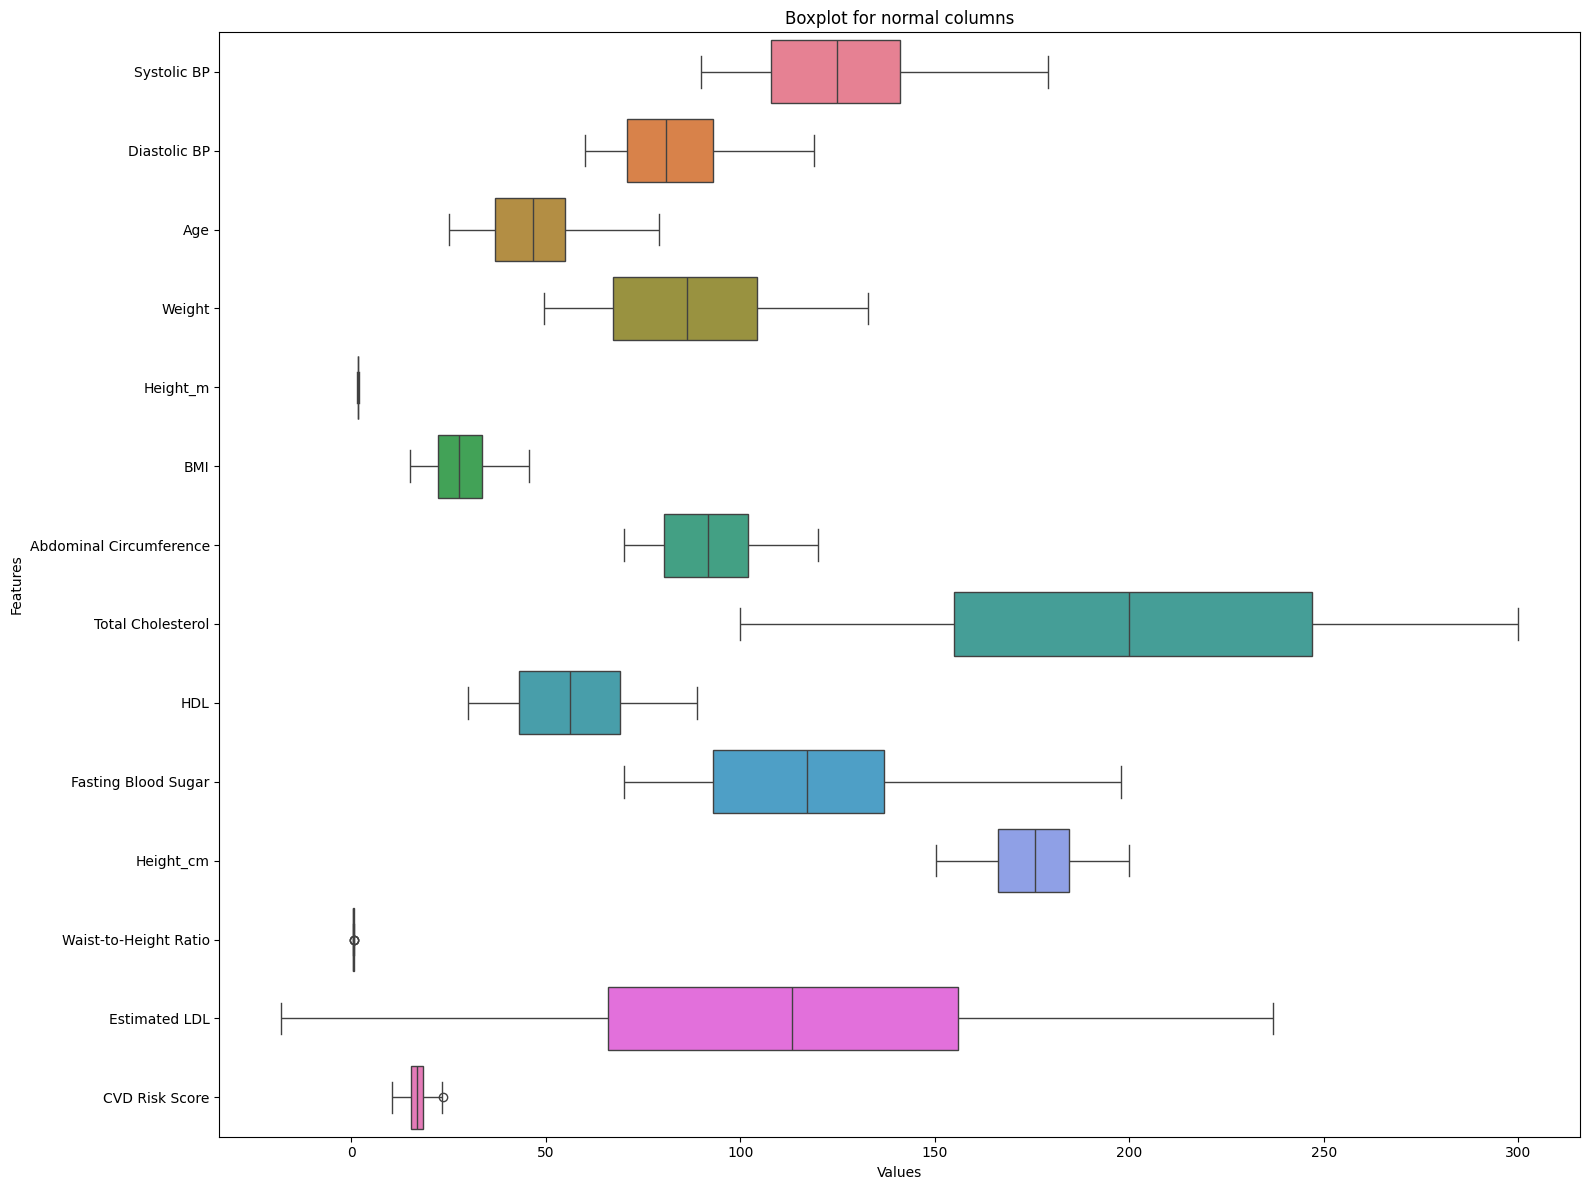

In [ ]:
# plot graphs to detect outliers
fig, ax = plt.subplots(figsize=(16,12))

# boxplot for normal skewed cols
sns.boxplot(data=X_train_num_cols, orient='h', ax=ax)
ax.set_title('Boxplot for normal columns')
ax.set_xlabel('Values')
ax.set_ylabel('Features')

plt.tight_layout()
plt.show()

Terlihat dari visualisasi boxplot, outlier hanya ditemukan di `Waist-to-Height Ratio` dan `CVD Risk Score`. Perlu cek berapa persentase outlier. Jika < 5%, maka tidak dilakukan capping Gaussian.

In [ ]:
def calculate_outlier_pct_normal(df, cols):
    for col in cols:
        std=df[col].std()
        mean=df[col].mean()
        lower_bound = mean - (std*3)
        upper_bound = mean + (std*3)

        outliers = df[
            (df[col] < lower_bound) | (df[col] > upper_bound)
        ]

        #calculate percentage outliers
        outliers_pct = len(outliers) / len(df[col]) * 100

        print(f'{col}: {outliers_pct:.2f}%')

# calculate outlier percentage before handling outliers
print(calculate_outlier_pct_normal(X_train_num_cols, num_cols))

Age: 0.00%
Weight: 0.00%
Height_m: 0.00%
BMI: 0.00%
Abdominal Circumference: 0.00%
Total Cholesterol: 0.00%
HDL: 0.00%
Fasting Blood Sugar: 0.00%
Height_cm: 0.00%
Waist-to-Height Ratio: 0.28%
Systolic BP: 0.00%
Diastolic BP: 0.00%
Estimated LDL: 0.00%
CVD Risk Score: 0.00%
None


X_train_num_cols memiliki outliers di bawah 5%, sehingga tidak dilakukan capping outliers.

### Feature Engineering - Feature Selection

Selecting the most relevant features for the training model to be smarter in predicting the target `CVD Risk Level`, using Pearson correlation (for normal distribution data).

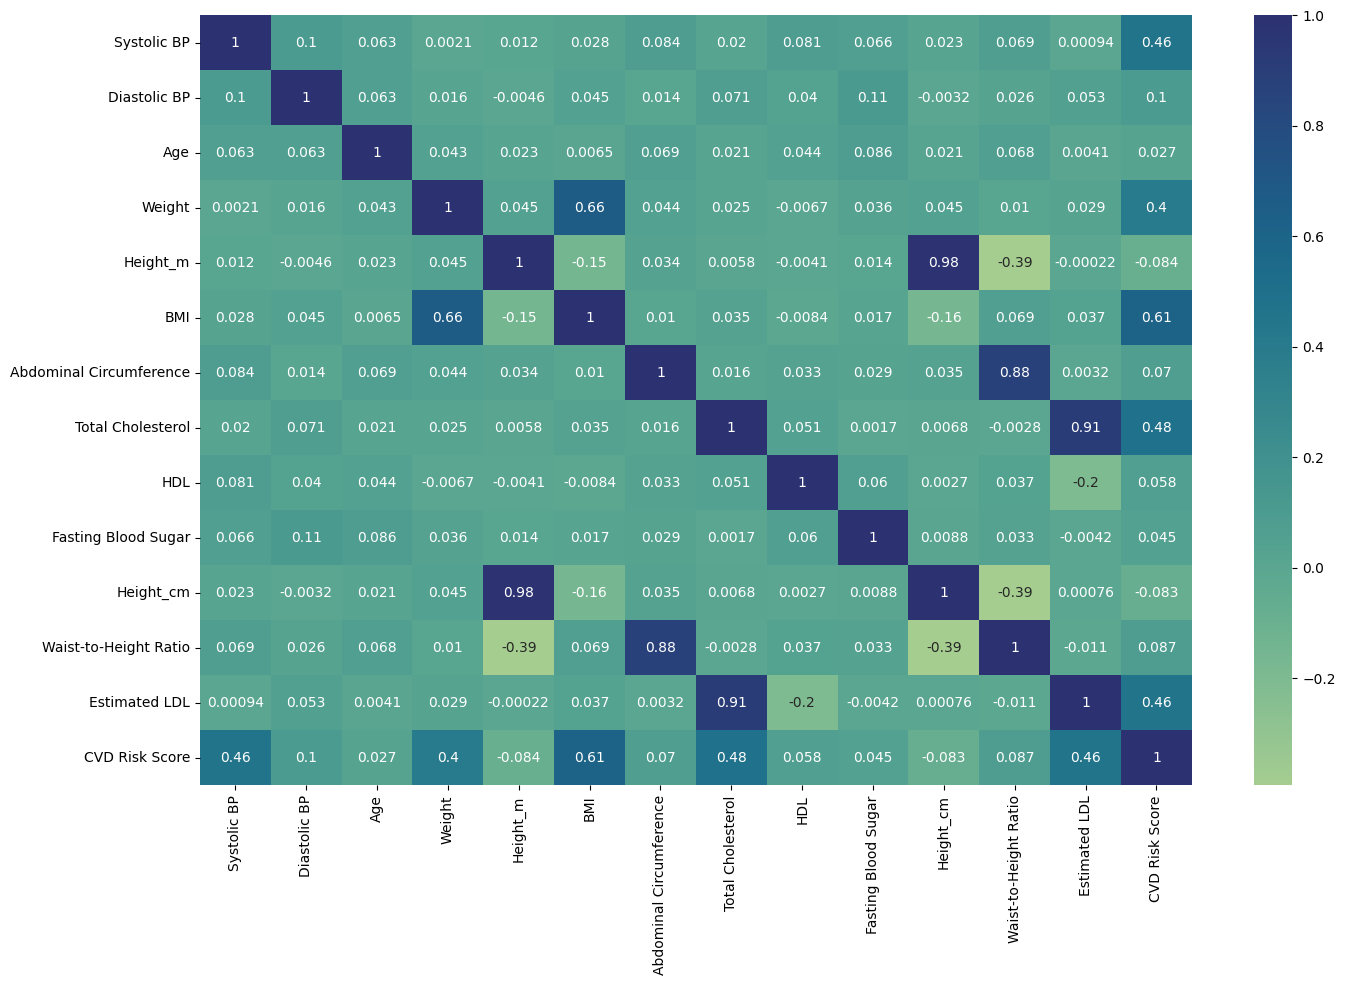

In [ ]:
# correlation between numerical features to detect multicolinearity

corr_num = X_train_num_cols.corr(method='pearson')

# viz correlation
plt.figure(figsize=(16,10))
sns.heatmap(
    corr_num,
    annot=True,
    cmap='crest'
)
plt.show()

- Feature `Height_cm` dan `Height_m` memiliki informasi yang sama dengan korelasi 0.98, sehingga drop salah satu. Drop `Height_m`.<br>
- Feature `Total Cholesterol` dan `Estimated LDL` memiliki korelasi 0.91, drop `Estimated LDL` karena `Total Cholesterol` lebih representatif.<br>
- Feature `Abdominal Circumference` dan `Waist-to-Height Ratio` memiliki korelasi 0.88, maka drop salah satu. Drop `Abdominal Circumference` karena `Waist-to-Height Ratio` lebih representatif.<br>
- Feature `CVD Risk Score` di-drop, karena memiliki informasi yang sama dengan target `CVD Risk Level`.<br>

In [ ]:
# drop numerical features that have multicolinearity
X_train_num_cols=X_train_num_cols.drop(columns=['Height_m', 'Estimated LDL', 'Abdominal Circumference', 'CVD Risk Score'])
X_test_num_cols=X_test_num_cols.drop(columns=['Height_m', 'Estimated LDL', 'Abdominal Circumference', 'CVD Risk Score'])

In [ ]:
# correlation numerical features to target y using ANOVA test
anova_results = []
num_cols = X_train_num_cols.columns

for col in num_cols:
    group_low = X_train_num_cols.loc[y_train == 'LOW', col]
    group_intermediary = X_train_num_cols.loc[y_train == 'INTERMEDIARY', col]
    group_high = X_train_num_cols.loc[y_train == 'HIGH', col]

    res = stats.f_oneway(
        group_low,
        group_intermediary,
        group_high
    )

    anova_results.append({
        'Feature': col,
        'Anova statistic': res.statistic,
        'p_value': res.pvalue
    })

anova_results=pd.DataFrame(anova_results)
# show anova results sorted by p_value
anova_results.sort_values(
    by='p_value',
    ascending=True
)

,Feature,Anova statistic,p_value
4,BMI,26.682209,4.926374e-12
6,HDL,21.535347,6.778799e-10
5,Total Cholesterol,15.438153,2.457381e-07
0,Systolic BP,15.055269,3.565632e-07
3,Weight,11.923371,7.564199e-06
7,Fasting Blood Sugar,3.733095,2.423167e-02
1,Diastolic BP,2.976580,5.139024e-02
2,Age,2.620763,7.321562e-02
9,Waist-to-Height Ratio,1.526404,2.177899e-01
8,Height_cm,0.688616,5.024940e-01


Berdasarkan uji ANOVA:
`Diastolic BP`, `Age`, `Waist-to-Height Ratio`, `Height_cm` memiliki p-value lebih dari 0.05/ critical value. Namun berdasarkan penelitian, Keempat features tersebut merupakan faktor untuk menentukan risk level penyakit Cardiovascular. Untuk itu, keempat features tetap dipertahankan.

In [ ]:
# preview X_train_num_cols
X_train_num_cols.head()

,Systolic BP,Diastolic BP,Age,Weight,BMI,Total Cholesterol,HDL,Fasting Blood Sugar,Height_cm,Waist-to-Height Ratio
133,98.0,72.0,35.000000,75.300,25.500,137.0,53.0,73.0,172.000,0.555
1348,101.0,91.0,57.000000,92.923,33.116,158.0,71.0,76.0,184.172,0.577
543,118.0,76.0,46.824338,57.500,21.900,238.0,73.0,126.0,162.000,0.520
454,130.0,94.0,39.000000,109.900,33.900,267.0,35.0,116.0,180.000,0.497
1056,128.0,97.0,75.000000,115.384,34.636,164.0,31.0,122.0,174.385,0.586


In [ ]:
# preview X_test_num_cols
X_test_num_cols.head()

,Systolic BP,Diastolic BP,Age,Weight,BMI,Total Cholesterol,HDL,Fasting Blood Sugar,Height_cm,Waist-to-Height Ratio
1430,164.0,78.0,57.0,51.845,23.094,211.0,30.000000,79.0,175.51,0.639
970,106.0,69.0,39.0,106.700,39.200,201.0,76.000000,127.0,165.00,0.645
666,140.0,72.0,53.0,87.900,28.700,230.0,34.000000,112.0,175.00,0.514
550,116.0,91.0,48.0,117.800,34.100,100.0,69.000000,150.0,186.00,0.394
526,98.0,60.0,58.0,85.500,25.500,111.0,56.236559,124.0,183.00,0.558


In [ ]:
# correlation between categorical features to detect multicolinearity

cat_cols = X_train.select_dtypes(
    include=['object']
).columns

chi_results = []

for col in cat_cols:
    contingency_table= pd.crosstab(
        X_train[col],
        y_train
    )
    res = stats.chi2_contingency(contingency_table)

    chi_results.append({
        'Feature': col,
        'Chi Statistic': res.statistic,
        'p_value': res.pvalue,
    })

chi_results=pd.DataFrame(chi_results)
# show chi results sorted by p_value
chi_results.sort_values(
    by='p_value',
    ascending=True
)

,Feature,Chi Statistic,p_value
2,Smoking Status,57.071521,4.046474e-13
3,Diabetes Status,49.153038,2.121062e-11
5,Family History of CVD,35.121390,2.363127e-08
4,Physical Activity Level,35.347806,3.940548e-07
6,Blood Pressure Category,24.845333,3.647169e-04
0,Sex,2.394436,3.020333e-01
1,Blood Pressure,1853.045571,3.853645e-01


`Sex` dan `Blood Pressure` di-drop karena tidak memiliki korelasi dengan target `CVD Risk Level` atau belum cukup bukti.

In [ ]:
# drop categorical features that have no correlation with target
X_train=X_train.drop(columns=['Sex', 'Blood Pressure'])
X_test=X_test.drop(columns=['Sex', 'Blood Pressure'])

In [ ]:
# redefine cat_cols
cat_cols = X_train.select_dtypes(
    include=['object']
).columns
cat_cols

Index(['Smoking Status', 'Diabetes Status', 'Physical Activity Level',
       'Family History of CVD', 'Blood Pressure Category'],
      dtype='object')

In [ ]:
# preview X_train categorical
X_train[cat_cols].head()

,Smoking Status,Diabetes Status,Physical Activity Level,Family History of CVD,Blood Pressure Category
133,Y,Y,High,N,Normal
1348,N,Y,High,Y,Hypertension Stage 2
543,Y,N,High,Y,Normal
454,Y,N,Low,Y,Hypertension Stage 1
1056,Y,N,Moderate,Y,Hypertension Stage 2


In [ ]:
# preview X_test categorical
X_test[cat_cols].head()

,Smoking Status,Diabetes Status,Physical Activity Level,Family History of CVD,Blood Pressure Category
1430,Y,Y,High,Y,Hypertension Stage 2
970,N,N,High,N,Normal
666,N,N,Moderate,Y,Hypertension Stage 2
550,N,N,Low,N,Hypertension Stage 2
526,Y,Y,Low,Y,Normal


In [ ]:
# concat numerical & categorical
X_train_final = pd.concat(
    [X_train_num_cols, X_train[cat_cols]],
    axis=1
)

X_test_final = pd.concat(
    [X_test_num_cols, X_test[cat_cols]],
    axis=1
)

# validate results, check shape
print('shape X_train_final: ',X_train_final.shape)
print('shape X_test_final: ',X_test_final.shape)

shape X_train_final:  (1070, 15)
shape X_test_final:  (459, 15)


Dari original features 21 kolom menjadi 15 features.

In [ ]:
# preview data
X_train_final.head()

,Systolic BP,Diastolic BP,Age,Weight,BMI,Total Cholesterol,HDL,Fasting Blood Sugar,Height_cm,Waist-to-Height Ratio,Smoking Status,Diabetes Status,Physical Activity Level,Family History of CVD,Blood Pressure Category
133,98.0,72.0,35.000000,75.300,25.500,137.0,53.0,73.0,172.000,0.555,Y,Y,High,N,Normal
1348,101.0,91.0,57.000000,92.923,33.116,158.0,71.0,76.0,184.172,0.577,N,Y,High,Y,Hypertension Stage 2
543,118.0,76.0,46.824338,57.500,21.900,238.0,73.0,126.0,162.000,0.520,Y,N,High,Y,Normal
454,130.0,94.0,39.000000,109.900,33.900,267.0,35.0,116.0,180.000,0.497,Y,N,Low,Y,Hypertension Stage 1
1056,128.0,97.0,75.000000,115.384,34.636,164.0,31.0,122.0,174.385,0.586,Y,N,Moderate,Y,Hypertension Stage 2


### Feature Encoding & Scaling using Pipeline

Scaling menggunakan StandardScaler untuk numerical features.<br>
Encode cat_cols yang biner categorical (karena bukan biner 2 angka, tapi 2 huruf: Y dan N). Maka dilakukan ordinalencoding juga agar berubah menjadi biner angka category.<br>
`Physical Activity Level` dan `Blood Pressure Category` merupakan ordinal category, perlu di encode ordinal.

In [ ]:
# numerical features
num_cols

Index(['Systolic BP', 'Diastolic BP', 'Age', 'Weight', 'BMI',
       'Total Cholesterol', 'HDL', 'Fasting Blood Sugar', 'Height_cm',
       'Waist-to-Height Ratio'],
      dtype='object')

In [ ]:
# numbers of num_cols
n_num = len(num_cols)
n_num

10

In [ ]:
# categorical features
cat_cols

Index(['Smoking Status', 'Diabetes Status', 'Physical Activity Level',
       'Family History of CVD', 'Blood Pressure Category'],
      dtype='object')

In [ ]:
# binary features
bin_cat = ['Smoking Status', 'Diabetes Status','Family History of CVD']

# numbers of binary features
n_bin = len(bin_cat)
n_bin

3

In [ ]:
# ordinal features
ord_cat = ['Physical Activity Level','Blood Pressure Category']

# numbers of ordinal features
n_ord = len(ord_cat)
n_ord

2

In [ ]:
# urutan ordinal physical activity level
ord_physical_level_category = ['Low', 'Moderate', 'High']

# urutan ordinal blood pressure category
ord_bp_category = ['Normal', 'Elevated', 'Hypertension Stage 1', 'Hypertension Stage 2']

In [ ]:
# set up scaling method for numerical features
scaler = StandardScaler()

# set up ordinal encoding for ordinal categorical features
enc_ord = OrdinalEncoder(
    categories=[ord_physical_level_category, ord_bp_category],
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

# set up ordinal encoding for binary categorical features
enc_bin = OrdinalEncoder(
    categories=[['N', 'Y']] * n_bin, # N becomes 0 and Y becomes 1
    handle_unknown='use_encoded_value',
    unknown_value=-1
)
def make_pipe(model):
    ''' preprocess to scale numerical features and categorical encoding'''
    preprocess = ColumnTransformer(
        transformers=[
            ('num_pipe', make_pipeline(
                mean_imputer,
                scaler),num_cols),
            ('bin_cat',enc_bin, bin_cat), # binary category tidak perlu di-encode lagi
            ('ord_cat', enc_ord, ord_cat),
        ],
        remainder='passthrough'
    )

    return make_pipeline(
        preprocess,
        model
    )

In [ ]:
# set up label encoder for target/label
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

y_train_encoded

array([1, 1, 0, ..., 0, 0, 1])

In [ ]:
# class target
le.classes_

array(['HIGH', 'INTERMEDIARY', 'LOW'], dtype=object)

## Model Definition
Cross validation untuk memilih baseline training model dengan performa terbaik antara SVM(SVC), KNN, Decision Tree (DT), Random Forest (RF), dan GradientBoost.

In [ ]:
# baseline model definition
models = {
    'SVM': SVC(random_state=10, probability=True),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=10),
    'Random Forest': RandomForestClassifier(random_state=10),
    'Gradient Boost': GradientBoostingClassifier(random_state=10)
}

In [ ]:
# set cross validation per model
skfold = StratifiedKFold(n_splits=5)
scoring = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'roc_auc_ovr'] # using macro for multiclass target

In [ ]:
# Looking for the best models in Cross Validation
name_models = []
cv_scores = 0
for name, model in models.items():
    cv = cross_validate(
        make_pipe(model), X_train_final, y_train_encoded, cv=skfold, scoring=scoring, n_jobs=-1)
    name_model={"Model": name}

    for metric in scoring:
        key="test_" + metric # "test_" fold validation_set
        mean = cv[key].mean()
        std = cv[key].std()
        name_model[f'{metric} lower range'] = mean - std
        name_model[f'{metric} upper range'] = mean + std

    roc_mean=cv['test_roc_auc_ovr'].mean()
    name_model['roc_auc_ovr_mean'] = roc_mean
    name_models.append(name_model)

# insert result scoring training per model to dataframe
df_cv = pd.DataFrame(name_models)

In [ ]:
# menampilkan hasil cross validation
df_cv.T

,0,1,2,3,4
Model,SVM,KNN,Decision Tree,Random Forest,Gradient Boost
accuracy lower range,0.613617,0.551093,0.547609,0.615564,0.656446
accuracy upper range,0.670496,0.585355,0.61127,0.653595,0.672526
precision_macro lower range,0.417858,0.356157,0.48374,0.45341,0.517073
precision_macro upper range,0.537387,0.542361,0.554235,0.556118,0.56133
recall_macro lower range,0.476565,0.421107,0.477737,0.480456,0.520956
recall_macro upper range,0.519806,0.459425,0.55001,0.524083,0.55385
f1_macro lower range,0.448816,0.394613,0.478627,0.454832,0.504194
f1_macro upper range,0.482963,0.443375,0.54983,0.513157,0.550697
roc_auc_ovr lower range,0.746972,0.658215,0.614846,0.775421,0.7524


- Berdasarkan percobaan training baseline model di cross validation, model `GradientBoost` adalah baseline model terbaik, dengan nilai metrics accuracy, precision macro, recall macro, f1 macro unggul diantara lainnya.
- Kelemahan `GradientBoost` adalah sedikit lebih rendah di metric ROC_AUC_OVR dari `Random Forest` di rata-rata 77%.
- `Random Forest` merupakan kandidat training baseline model terbaik kedua. Nilai metric sedikit di bawah `GradientBoost` tapi sedikit unggul di ROC_AUC_OVR dengan rata-rata 80%.
- `SVM` merupakan kandidat training baseline model terbaik ketiga, unggul di f1 macro dan roc_auc_ovr daripada `Decision Tree`.
- `KNN` adalah model dengan performa terendah diantara kelima model, dengan precision macro 35-45% dan f1 macro 39-44%.

## Model Evaluation Before Tuning: GradientBoost

In [ ]:
# fit pipeline GradientBoost
pipe_gradboost = make_pipe(GradientBoostingClassifier(random_state=10))
pipe_gradboost.fit(X_train_final, y_train_encoded)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num_pipe',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer()),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['Systolic BP', 'Diastolic BP', 'Age', 'Weight', 'BMI',
       'Total Cholesterol', 'HDL', 'Fasting Blood Sugar', 'Height_cm',
       'Waist-to-Height Ratio'],
      dtype='object')),
                                                 ('bi...
                                                   'Diabetes Status',
                                                   'Family History of CVD']),
                                                 ('ord_cat',
                                                  OrdinalEncoder(categories=[['Low',
                                                                              'Moderate',
                                                                              'High'],
                                                                             ['Normal',
                                                                              'Elevated',
                                                                              'Hypertension '
                                                                              'Stage '
                                                                              '1',
                                                                              'Hypertension '
                                                                              'Stage '
                                                                              '2']],
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-1),
                                                  ['Physical Activity Level',
                                                   'Blood Pressure '
                                                   'Category'])])),
                ('gradientboostingclassifier',
                 GradientBoostingClassifier(random_state=10))])

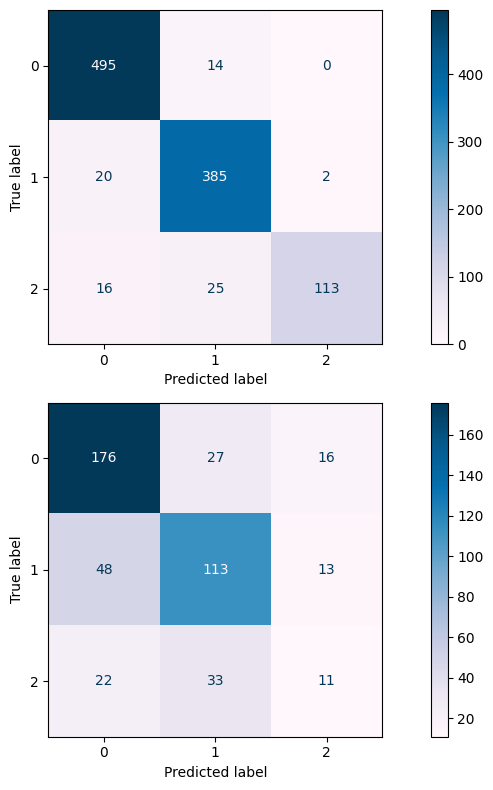

In [ ]:
# viz the confusion matrix

fig, axes = plt.subplots(2,1, figsize=(10,8))

# plot confusion matrix - training set
train_matrix = ConfusionMatrixDisplay.from_estimator(pipe_gradboost, X_train_final, y_train_encoded, cmap='PuBu', ax=axes[0])

# plot confusion matrix - testing set
test_matrix = ConfusionMatrixDisplay.from_estimator(pipe_gradboost, X_test_final, y_test_encoded, cmap='PuBu', ax=axes[1])

plt.tight_layout()
plt.show()

In [ ]:
# transform predict
y_pred_train = pipe_gradboost.predict(X_train_final)
y_pred_test = pipe_gradboost.predict(X_test_final)

# Show classification report
print('Classification report - GradientBoost - Training set')
print(classification_report(y_train_encoded, y_pred_train))
print('Classification report - GradientBoost - Testing set')
print(classification_report(y_test_encoded, y_pred_test))

Classification report - GradientBoost - Training set
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       509
           1       0.91      0.95      0.93       407
           2       0.98      0.73      0.84       154

    accuracy                           0.93      1070
   macro avg       0.94      0.88      0.91      1070
weighted avg       0.93      0.93      0.93      1070

Classification report - GradientBoost - Testing set
              precision    recall  f1-score   support

           0       0.72      0.80      0.76       219
           1       0.65      0.65      0.65       174
           2       0.28      0.17      0.21        66

    accuracy                           0.65       459
   macro avg       0.55      0.54      0.54       459
weighted avg       0.63      0.65      0.64       459



- Dari classification report dan confusion matrix, model dapat dikatakan memiliki indikasi overfitting.
- Model sangat baik pada training set, dilihat pada nilai rata-rata macro avg masing-masing metrics diatas 88%. Namun, model sangat buruk pada testing set, di mana nilai rata-rata macro avg masing-masing metric: 55% precision macro, 54% recall macro, dan 54% f1 macro.
- Berdasarkan confusion matrix, model dapat memprediksi kelas 0 (High) secara benar sebanyak 176 (True Positive), dan False Negative kelas 1 sebanyak 48 dan kelas 2 sebanyak 22. Artinya model mampu memprediksi kelas 0 sebanyak 71%.
- Berdasarkan confusion matrix, model dapat memprediksi kelas kelas 1 (Intermediary) secara benar sebanyak 113, dan False Negative kelas 0 sebanyak 27 dan kelas 2 sebanyak 33. Artinya model mampu memprediksi kelas 1 sebanyak 65%.
- Berdasarkan confusion matrix, model dapat memprediksi kelas kelas 2 (Low) secara benar sebanyak 11, dan False Negative kelas 0 sebanyak 16 dan kelas 1 sebanyak 13. Artinya model mampu memprediksi kelas 2 sebanyak 27%.
- **Model paliing baik dalam klasifikasi kelas 0 atau CVD Risk Level High**.

## Training Model with Hyperparameter Tuning

Di cross validation, diketahui bahwa model GradientBoost adalah model baseline training model terbaik daripada SVM, Random Forest, Decision Tree, dan KNN. <br>
Di section ini, dilakukan hyperparameter tuning dengan RandomizedSearchCV, karena keterbatasan spesifikasi PC meskipun dataset termasuk ukuran kecil (1529 baris) < 500.000 dan berukuran 164 kb (Lisa, L., dkk, 2023).

In [ ]:
# check parameter keys in gardientboost
pipe_gradboost.get_params().keys()

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'columntransformer', 'gradientboostingclassifier', 'columntransformer__force_int_remainder_cols', 'columntransformer__n_jobs', 'columntransformer__remainder', 'columntransformer__sparse_threshold', 'columntransformer__transformer_weights', 'columntransformer__transformers', 'columntransformer__verbose', 'columntransformer__verbose_feature_names_out', 'columntransformer__num_pipe', 'columntransformer__bin_cat', 'columntransformer__ord_cat', 'columntransformer__num_pipe__memory', 'columntransformer__num_pipe__steps', 'columntransformer__num_pipe__transform_input', 'columntransformer__num_pipe__verbose', 'columntransformer__num_pipe__simpleimputer', 'columntransformer__num_pipe__standardscaler', 'columntransformer__num_pipe__simpleimputer__add_indicator', 'columntransformer__num_pipe__simpleimputer__copy', 'columntransformer__num_pipe__simpleimputer__fill_value', 'columntransformer__num_pipe__simpleimputer__keep_empty_features', 

In [ ]:
# Hyperparameter Tuning with RandomizedSearchCV

# Set up parameter for GradientBoost to be more conservative to prevent overfitting
param_gradboost = {
    'gradientboostingclassifier__learning_rate': uniform(0.01,0.75),  # default 0.1
    'gradientboostingclassifier__max_depth': randint(1,6), # random integer from 0 to 5 (3 as default)
    'gradientboostingclassifier__subsample': uniform(0.5,1), # default 1
    'gradientboostingclassifier__min_samples_leaf': randint(1,11), # default 1
    'gradientboostingclassifier__max_features': ['sqrt', 'log2', None]
}

# set up RandomizedSearchCV
random_search_gradboost = RandomizedSearchCV(pipe_gradboost,
                                       param_distributions=param_gradboost,
                                       n_iter=30,
                                       scoring='f1_macro',
                                       cv=skfold,
                                       verbose=2,
                                       n_jobs=1)

# Fit RandomizedSearchCV to GradientBoost Model
random_search_gradboost.fit(X_train_final, y_train_encoded)

# best hyperparameters
print('Best Hyperparameters for GradientBoost: ', random_search_gradboost.best_params_)

# best precision macro
print('Best F1 Macro for GradientBoost: ', random_search_gradboost.best_score_)
# save best GradientBoost model to a variable
best_gradboost_model = random_search_gradboost.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END gradientboostingclassifier__learning_rate=0.29374059456966795, gradientboostingclassifier__max_depth=4, gradientboostingclassifier__max_features=sqrt, gradientboostingclassifier__min_samples_leaf=4, gradientboostingclassifier__subsample=0.7616448948753675; total time=   0.8s
[CV] END gradientboostingclassifier__learning_rate=0.29374059456966795, gradientboostingclassifier__max_depth=4, gradientboostingclassifier__max_features=sqrt, gradientboostingclassifier__min_samples_leaf=4, gradientboostingclassifier__subsample=0.7616448948753675; total time=   0.8s
[CV] END gradientboostingclassifier__learning_rate=0.29374059456966795, gradientboostingclassifier__max_depth=4, gradientboostingclassifier__max_features=sqrt, gradientboostingclassifier__min_samples_leaf=4, gradientboostingclassifier__subsample=0.7616448948753675; total time=   0.8s
[CV] END gradientboostingclassifier__learning_rate=0.29374059456966795, gradientboo

In [ ]:
# show best model GradientBoost
best_gradboost_model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num_pipe',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer()),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['Systolic BP', 'Diastolic BP', 'Age', 'Weight', 'BMI',
       'Total Cholesterol', 'HDL', 'Fasting Blood Sugar', 'Height_cm',
       'Waist-to-Height Ratio'],
      dtype='object')),
                                                 ('bi...
                                                                              'Hypertension '
                                                                              'Stage '
                                                                              '1',
                                                                              'Hypertension '
                                                                              'Stage '
                                                                              '2']],
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-1),
                                                  ['Physical Activity Level',
                                                   'Blood Pressure '
                                                   'Category'])])),
                ('gradientboostingclassifier',
                 GradientBoostingClassifier(learning_rate=0.38336324232759444,
                                            max_depth=2, max_features='sqrt',
                                            min_samples_leaf=10,
                                            random_state=10,
                                            subsample=0.8234867731864778))])

Berdasarkan hasil RandomizedSearchCV, model menghasilkan performa terbaik (f1_macro) di konfigurasi:<br>
1. learning_rate = 0.38,
2. max_depth = 2,
3. max_features = 'sqrt'
3. min_sample_leaf = 10,
4. subsample = 0.82

Best F1 macro score di rata-rata 55%.

In [ ]:
# predict target using hyperparameter tuning
y_pred_train_tuned = best_gradboost_model.predict(X_train_final)
y_pred_test_tuned = best_gradboost_model.predict(X_test_final)

# Show F1_Macro score
print('F1 Macro Score - train set: ', f1_score(y_train_encoded, y_pred_train_tuned, average='macro'))
print('F1 Macro Score - test set: ', f1_score(y_test_encoded, y_pred_test_tuned, average='macro'))

F1 Macro Score - train set:  0.8482088361901101
F1 Macro Score - test set:  0.5182239683119493


Model masih terindikasi overfitting setelah hyperparameter tuning, dengan nilai F1 Macro Train set jauh lebih tinggi di 84% dan F1 Macro Test set di 51%, di mana gap train dan test set > 5%.

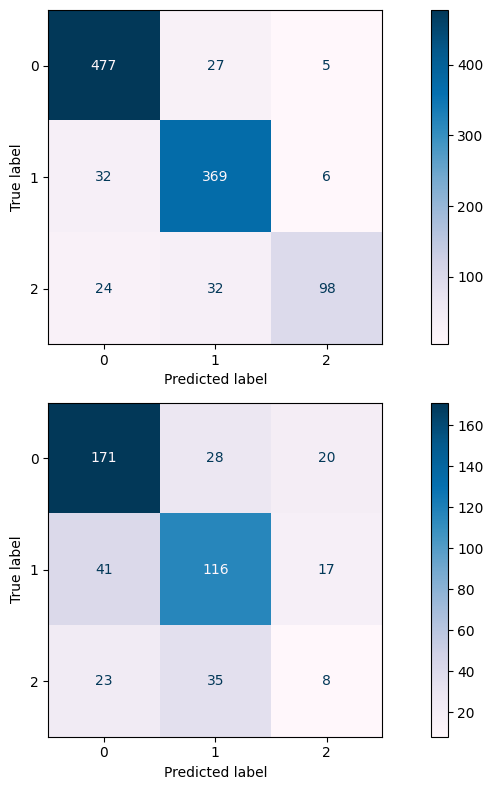

In [ ]:
# Viz confusion matrix GradientBoost after hyperparameter tuning
fig, axes = plt.subplots(2,1, figsize=(10,8))

# plot confusion matrix - training set
train_matrix = ConfusionMatrixDisplay.from_estimator(best_gradboost_model, X_train_final, y_train_encoded, cmap='PuBu', ax=axes[0])

# plot confusion matrix - testing set
test_matrix = ConfusionMatrixDisplay.from_estimator(best_gradboost_model, X_test_final, y_test_encoded, cmap='PuBu', ax=axes[1])

plt.tight_layout()
plt.show()

- Setelah dilakukan hyperparameter tuning, model masih terindikasi overfitting dengan sempurna di training set, namun model masih banyak kesalahan di testing set. <br>
- Ada perubahan di mana Prediksi kelas 0 (High) turun dari 176 menjadi 171 di kelas 0 (High); Namun Prediksi kelas 1 (Intermediary) naik dari 113 menjadi 116 dan kelas 2 turun dari 11 menjadi 8 di test set setelah hyperparameter tuning. Ini menandakan algoritma RandomSearchCV berusaha mencarikan hyperparameter untuk tuning model Gradientboost agar harmonik antara precision macro dan precision macro dalam memprediksi multiclass (F1 Macro).

### Before vs After Tuning Comparison

In [ ]:
# before tuning
print("===TEST SET BEFORE HYPERPARAMETER TUNING===")
print(classification_report(y_test_encoded, y_pred_test))
print('='*40)
print("===TEST SET AFTER HYPERPARAMETER TUNING===")
print(classification_report(y_test_encoded, y_pred_test_tuned))

===TEST SET BEFORE HYPERPARAMETER TUNING===
              precision    recall  f1-score   support

           0       0.72      0.80      0.76       219
           1       0.65      0.65      0.65       174
           2       0.28      0.17      0.21        66

    accuracy                           0.65       459
   macro avg       0.55      0.54      0.54       459
weighted avg       0.63      0.65      0.64       459

===TEST SET AFTER HYPERPARAMETER TUNING===
              precision    recall  f1-score   support

           0       0.73      0.78      0.75       219
           1       0.65      0.67      0.66       174
           2       0.18      0.12      0.14        66

    accuracy                           0.64       459
   macro avg       0.52      0.52      0.52       459
weighted avg       0.62      0.64      0.63       459



- Perbandingan model GradientBoost before vs after tuning, model GradientBoost after tuning diketahui tidak ada perubahan signifikan.
- Perubahan sedikit terlihat model lebih baik dalam prediksi kelas 1 atau Intermediary (F1 score kelas 1 naik dari 65% menjadi 66%), Dibuktikan dengan plot confusion matrix yang menunjukkan performa naik untuk prediksi kelas Intermediary.

- Untuk model inference, digunakan GradientBoost dengan versi hyperparameter tuning, karena prediksi antar kelas nya lebih baik/seimbang.

## Conclusion & Recommendation

1. Dari kelima model SVM, KNN, Decision Tree, Random Forest, dan GradientBoost, GradientBoost merupakan baseline training model terbaik.
2. Model GradientBoost memiliki indikasi overfitting. Model GradientBoost dengan konfigurasi hyperparameter hasil RandomizedSearchCV, sedikit menaikkan skor F1 kelas 1 (Intermediary), namun model masih indikasi overfitting. F1 Macro Train set: 84% dan F1 Macro test set: 54%.
3. Hasil hyperparameter tuning, model GradientBoost dapat baik dalam memprediksi kelas 0 (High Level CVD) dan kelas 1 (Intermediary Level CVD), namun masih kurang dalam memprediksi kelas 2 (Low Level CVD).
4. Jika model salah prediksi user di yang actual nya kelas 2 (Low Level CVD), maka user tetap mendapatkan edukasi untuk penanganan CVD. Karena CVD dapat sewaktu-waktu terjadi yang dikarenakan umur yang semakin tua, dan pola hidup.
5. Rekomendasi untuk user kelas 0 atau **High CVD Risk Level**: Konsultasikan segera dengan dokter dan dikombinasikan dengan terapi obat atas resep dokter, pola gaya hidup ketat, rutin melakukan prosedur medis.
6. Rekomendasi untuk user kelas 1 atau **Intermediary CVD Risk Level**: Pada tingkat resiko sedang, perlu segera dikonsultasikan dengan dokter dan dikombinasikan dengan perbaikan pola hidup dan aktivitas fisik rutin, rutin cek kesehatan.

### Justification & Further Improvement
1. Percobaan model XGBoost menggunakan hyperparameter yang lengkap, karena XGboost memiliki parameter regularisasi ketat seperi l1 dan l2.
2. Dilakukan menggunakan algoritma GridSearchCV untuk mencari hyperparameter terbaik untuk mengatasi model overfit pada model di PC yang memiliki spesifikasi lebih tinggi (RAM min 16gb).
2. Ditambah dataset yang berasal dari Indonesia, agar lebih representatif untuk user Indonesia.

## Model Saving for Model Inference

In [ ]:
# save best model GradientBoost

with open ('deployment/src/best_gradboost_model.pkl', 'wb') as model_file:
    pickle.dump(best_gradboost_model, model_file)

with open('deployment/src/label_encoder.pkl', 'wb') as label_encoder_file:
    pickle.dump(le, label_encoder_file)